In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report



import pandas as pd

df = pd.read_csv("Churn_Modelling - Churn_Modelling.csv")

print("Dataset shape:", df.shape)
display(df.head())

print(df["Exited"].value_counts())

Dataset shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Exited
0    7963
1    2037
Name: count, dtype: int64


In [14]:
# Remove identifier/name columns because they do not provide useful model input.
X = df.drop(columns=["RowNumber", "CustomerId", "Surname", "Exited"])
y = df["Exited"]

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Categorical features: ['Geography', 'Gender']


C:\Users\rajva\AppData\Local\Temp\ipykernel_218284\3558428583.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object"]).columns.tolist()


Training data shape: (8000, 13)
Testing data shape: (2000, 13)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                      │ (None, 16)                  │             224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 369 (1.44 KB)

 Trainable params: 369 (1.44 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7917 - loss: 0.5120 - val_accuracy: 0.8000 - val_loss: 0.4521
Epoch 2/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8061 - loss: 0.4346 - val_accuracy: 0.8244 - val_loss: 0.4181
Epoch 3/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8242 - loss: 0.4083 - val_accuracy: 0.8475 - val_loss: 0.3969
Epoch 4/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8356 - loss: 0.3916 - val_accuracy: 0.8512 - val_loss: 0.3772
Epoch 5/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8430 - loss: 0.3778 - val_accuracy: 0.8575 - val_loss: 0.3610
Epoch 6/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8459 - loss: 0.3674 - val_accuracy: 0.8644 - val_loss: 0.3500
Epoch 7/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8489 - loss: 0.3603 - val_accuracy: 0.8644 - val_loss: 0.3429
Epoch 8/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8491 - loss: 0.3555 - val_accuracy: 0.

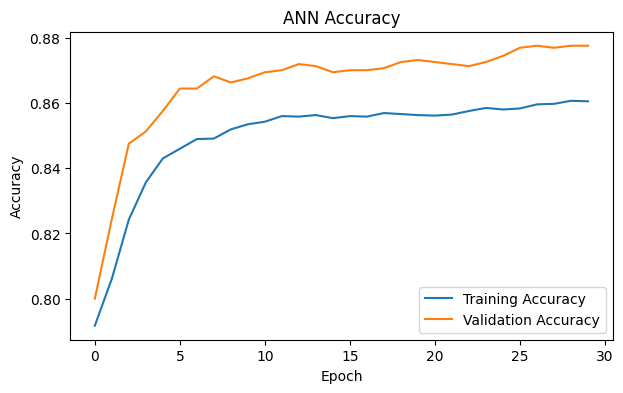

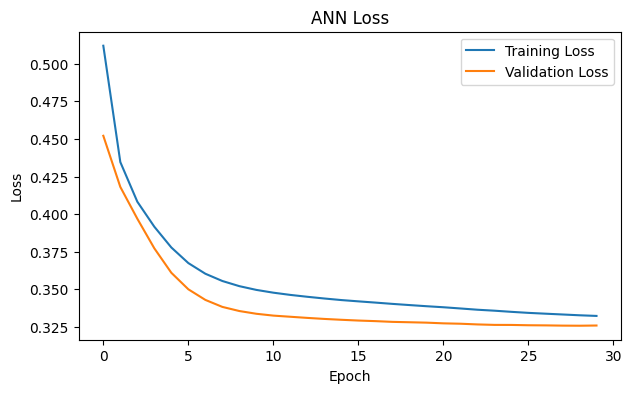

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Accuracy: 0.861

Confusion Matrix:
[[1532   61]
 [ 217  190]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.96      0.92      1593
           1       0.76      0.47      0.58       407

    accuracy                           0.86      2000
   macro avg       0.82      0.71      0.75      2000
weighted avg       0.85      0.86      0.85      2000



In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Keras dense layers expect regular numeric arrays.
X_train_processed = X_train_processed.astype("float32")
X_test_processed = X_test_processed.astype("float32")

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)


# If this import fails, run this in a separate cell:
# %pip install tensorflow
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)

model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history = model.fit(
    X_train_processed,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)


plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Loss")
plt.legend()
plt.show()


probabilities = model.predict(X_test_processed)
predictions = (probabilities >= 0.5).astype(int).ravel()

print("Accuracy:", accuracy_score(y_test, predictions))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))
print("\nClassification Report:")
print(classification_report(y_test, predictions, zero_division=0))

In [ ]:
ANN Practical – Important Terms and Definitions
1. Algorithm and neural network
Term	Definition / Working
ANN	Artificial Neural Network. Inspired by the human brain; consists of interconnected neurons arranged in layers.
Supervised Learning	Model learns using labelled input and output data.
Binary Classification	Predicting one of two classes, such as 0 or 1.
Input Layer	Receives input features from the dataset.
Hidden Layer	Learns patterns and relationships from input data.
Output Layer	Produces the final prediction.
Neuron	Basic processing unit that calculates weighted sum, adds bias and applies activation.
Weight	Determines the importance of an input.
Bias	Additional learnable value that adjusts neuron output.
Activation Function	Introduces non-linearity into the neural network.
Forward Propagation	Passes inputs through layers to generate predictions.
Backpropagation	Calculates gradients of errors to update weights.
Optimizer	Algorithm used to update weights and minimize loss.

2. Activation functions
Function	Full form / Definition	Formula
ReLU	Rectified Linear Unit. Returns zero for negative values and the same value for positive inputs.	\(f(x)=\max(0,x)\)
Sigmoid	Converts values into a range between 0 and 1.	\(f(x)=\frac{1}{1+e^{-x}}\)
Leaky ReLU	Allows a small negative output to reduce dying ReLU.	\(f(x)=\max(0.01x,x)\)
Softmax	Converts multiple output scores into probabilities whose sum is 1.	\(\frac{e^{z_i}}{\sum_j e^{z_j}}\)

3. Training and preprocessing terms
Term	Full form / Definition / Working
Epoch	One complete pass through the entire training dataset.
Batch Size	Number of training records processed before a weight update.
Iteration	One batch-processing and weight-update step.
Learning Rate	Controls how much weights change during each update.
Overfitting	Model learns training data too closely and generalizes poorly.
Underfitting	Model fails to learn important patterns from data.
Hyperparameter	Model setting selected before or during training, e.g. neurons, epochs and batch size.
StandardScaler	Standardizes numerical data to mean 0 and standard deviation 1.
OneHotEncoder	Converts categorical values into binary columns.
Normalization	Scales values to a specified range, commonly 0–1.
Standardization	Transforms data using mean and standard deviation.
Data Leakage	When information from testing data improperly influences training.
EarlyStopping	Stops training when the monitored validation metric stops improving.

StandardScaler formula:
\[
Z=\frac{X-\mu}{\sigma}
\]

4. Model compilation terms
Term	Full form / Definition / Working
TensorFlow	Open-source machine learning and deep learning framework developed by Google.
Keras	High-level API used to build and train neural networks.
Sequential	Model architecture where layers are arranged one after another.
Dense	Fully connected neural network layer.
Adam	Adaptive Moment Estimation; optimizer that adapts learning rates using gradient estimates.
Binary Crossentropy	Loss function used for binary classification.
Loss Function	Measures the difference between actual and predicted outputs.
Model Summary	Displays layers, output shapes and trainable parameters.

Binary Crossentropy formula:
\[
L=-[y\log(p)+(1-y)\log(1-p)]
\]

Where \(y\) is actual output and \(p\) is predicted probability.

5. Model evaluation – Every important term
Very important for viva
A. Accuracy
Definition: Measures the percentage of total predictions that are correct.

Formula:
\[
Accuracy=\frac{TP+TN}{TP+TN+FP+FN}
\]

Working: Adds correct positive and negative predictions and divides by total predictions.
B. Confusion Matrix
Definition: A table used to evaluate a classification model by comparing actual and predicted classes.
	Predicted 0	Predicted 1
Actual 0	TN	FP
Actual 1	FN	TP

C. Four confusion matrix terms
Term	Full form	Definition
TP	True Positive	Actually left and predicted left.
TN	True Negative	Actually stayed and predicted stayed.
FP	False Positive	Actually stayed but predicted left.
FN	False Negative	Actually left but predicted stayed.

D. Precision
Definition: Out of all positive predictions, how many are actually positive?

Formula:
\[
Precision=\frac{TP}{TP+FP}
\]

Working: Measures correctness of positive predictions.

Example: Out of 100 customers predicted to leave, 90 actually left. Precision = 90%.
E. Recall (Sensitivity)
Definition: Out of all actual positive cases, how many were correctly identified?

Formula:
\[
Recall=\frac{TP}{TP+FN}
\]

Working: Measures how many actual churners the model successfully identifies.

Example: Out of 100 customers who actually left, model identifies 80. Recall = 80%.
F. F1-score
Definition: Harmonic mean of precision and recall.

Formula:
\[
F1=2\times\frac{Precision\times Recall}
{Precision+Recall}
\]

Working: Balances precision and recall into one metric.
G. Support
Definition: Number of actual samples belonging to each class in the testing dataset.

Formula:
\[
Support=TP+FN \quad \text{for class 1}
\]

\[
Support=TN+FP \quad \text{for class 0}
\]

H. Specificity
Definition: Measures how many actual negative cases are correctly identified.

Formula:
\[
Specificity=\frac{TN}{TN+FP}
\]

I. Classification Report
Definition: A summary containing precision, recall, F1-score and support for each class.
J. Threshold
Definition: A cutoff value used to convert predicted probabilities into classes.

In our practical, threshold = 0.5.
- Probability ≥ 0.5 → Class 1.
- Probability below 0.5 → Class 0.

6. Important library functions – one-line revision
Function	Purpose
pd.read_csv()	Reads CSV dataset.
df.head()	Displays first five rows.
df.shape	Returns rows and columns.
df.drop()	Removes columns.
df.select_dtypes()	Selects columns by datatype.
train_test_split()	Splits data into training and testing.
fit_transform()	Learns and applies preprocessing.
transform()	Applies learned preprocessing.
model.compile()	Configures optimizer, loss and metrics.
model.fit()	Trains the model.
model.predict()	Generates predictions.
model.summary()	Displays ANN architecture.
accuracy_score()	Calculates accuracy.
confusion_matrix()	Generates confusion matrix.
classification_report()	Displays precision, recall, F1 and support.
plt.plot()	Draws graphs.
plt.show()	Displays graphs.

7. Important formulas – all together
Concept	Formula
ReLU	\(f(x)=\max(0,x)\)
Sigmoid	\(f(x)=1/(1+e^{-x})\)
StandardScaler	\(Z=(X-\mu)/\sigma\)
Weighted Sum	\(z=\sum w_ix_i+b\)
Accuracy	\((TP+TN)/Total\)
Precision	\(TP/(TP+FP)\)
Recall	\(TP/(TP+FN)\)
F1-score	\(2PR/(P+R)\)
Specificity	\(TN/(TN+FP)\)
Iterations per epoch	Training samples / Batch size